In [1]:
# ============================================================
# 03_baselines.ipynb — Cell 1: Setup & Config
# ============================================================
# TF-IDF + Logistic Regression baselines for both targets:
#   - recommendation_status (3 classes, imbalanced)
#   - rating_band (3 ordinal classes, imbalanced)
#
# This cell only prepares the environment and shared helpers.
# No data is read or written here.
# ============================================================

from __future__ import annotations

import json
from pathlib import Path

import numpy as np
import polars as pl
import joblib

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)

# --- Shared seed (same as Part B, for end-to-end reproducibility) ----------
SPLIT_SEED = 2026
MODEL_SEED = SPLIT_SEED  # TF-IDF is deterministic; LogReg uses this for solver

# --- Project paths ---------------------------------------------------------
PROJECT_ROOT = Path("/home/jvd/Desktop/persian-nlp-pipeline")
SPLITS_DIR   = PROJECT_ROOT / "data" / "splits"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"

TRAIN_SUPERVISED_CSV = SPLITS_DIR / "train_supervised.csv"
VALIDATION_CSV       = SPLITS_DIR / "validation.csv"
TEST_CSV             = SPLITS_DIR / "test.csv"

# --- Output paths (written by later cells) ---------------------------------
TFIDF_REC_PATH      = ARTIFACTS_DIR / "tfidf_recommendation.joblib"
TFIDF_BAND_PATH     = ARTIFACTS_DIR / "tfidf_rating_band.joblib"
BASELINE_METRICS_JSON = ARTIFACTS_DIR / "baseline_metrics.json"

# --- rating_band ordinal encoding (per split_manifest.json) ----------------
BAND_ORDINAL = {"low": 0, "medium": 1, "high": 2}

# --- Fail-fast: input files must exist -------------------------------------
for _p in (TRAIN_SUPERVISED_CSV, VALIDATION_CSV, TEST_CSV):
    assert _p.exists(), f"Missing split file: {_p}"

# ============================================================
# Shared metric helpers (reused by Transformer notebooks later)
# ============================================================

def compute_classification_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    labels: list[str] | None = None,
) -> dict:
    """
    Compute the full metric suite required by the project Definition:
      - Accuracy
      - Macro F1
      - Macro Precision, Macro Recall
      - Per-class Precision / Recall / F1
      - Balanced Accuracy
      - Confusion Matrix

    Parameters
    ----------
    y_true, y_pred : array-like of shape (n,)
        Ground-truth and predicted labels (strings or ints).
    labels : list, optional
        The canonical label order. If None, inferred from sorted union.
        Always pass this explicitly to keep the confusion matrix order stable.

    Returns
    -------
    dict with all metrics, JSON-serializable (no numpy scalars).
    """
    if labels is None:
        labels = sorted(set(y_true) | set(y_pred))

    # Core scalars
    acc    = accuracy_score(y_true, y_pred)
    bal_acc = balanced_accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro", labels=labels, zero_division=0)
    macro_p, macro_r, _, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", labels=labels, zero_division=0
    )

    # Per-class metrics
    p_per, r_per, f1_per, support = precision_recall_fscore_support(
        y_true, y_pred, labels=labels, zero_division=0
    )
    per_class = {
        label: {
            "precision": float(p_per[i]),
            "recall": float(r_per[i]),
            "f1": float(f1_per[i]),
            "support": int(support[i]),
        }
        for i, label in enumerate(labels)
    }

    # Confusion matrix (rows = true, cols = predicted)
    cm = confusion_matrix(y_true, y_pred, labels=labels).tolist()

    return {
        "accuracy": float(acc),
        "balanced_accuracy": float(bal_acc),
        "macro_f1": float(macro_f1),
        "macro_precision": float(macro_p),
        "macro_recall": float(macro_r),
        "per_class": per_class,
        "confusion_matrix": cm,
        "labels_order": list(labels),
    }


def ordinal_distance_error(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    ordinal_map: dict[str, int],
) -> float:
    """
    Mean absolute ordinal distance between predicted and true labels.

    For rating_band: low=0, medium=1, high=2.
    Confusing low with high costs 2; confusing low with medium costs 1.
    This is the metric Definition requires for Task B.
    """
    true_ord = np.array([ordinal_map[v] for v in y_true])
    pred_ord = np.array([ordinal_map[v] for v in y_pred])
    return float(np.mean(np.abs(true_ord - pred_ord)))


print("Part C (baselines) environment ready.")
print(f"PROJECT_ROOT : {PROJECT_ROOT}")
print(f"SPLIT_SEED   : {SPLIT_SEED}")
print(f"MODEL_SEED   : {MODEL_SEED}")
print(f"BAND_ORDINAL : {BAND_ORDINAL}")
print()
print("Planned outputs (written by later cells):")
for p in (TFIDF_REC_PATH, TFIDF_BAND_PATH, BASELINE_METRICS_JSON):
    print(f"  {p.relative_to(PROJECT_ROOT)}")

Part C (baselines) environment ready.
PROJECT_ROOT : /home/jvd/Desktop/persian-nlp-pipeline
SPLIT_SEED   : 2026
MODEL_SEED   : 2026
BAND_ORDINAL : {'low': 0, 'medium': 1, 'high': 2}

Planned outputs (written by later cells):
  artifacts/tfidf_recommendation.joblib
  artifacts/tfidf_rating_band.joblib
  artifacts/baseline_metrics.json


In [2]:
# ============================================================
# 03_baselines.ipynb — Cell 2: Load Splits & Verify
# ============================================================
# Goal:
#   - load the three split CSVs with only the needed columns
#   - verify row counts against split_manifest.json
#   - print class distributions per split for audit
# No files are written here.
# ============================================================

# --- 1. Read split_manifest.json -------------------------------------------
with (SPLITS_DIR / "split_manifest.json").open("r", encoding="utf-8") as f:
    manifest = json.load(f)

manifest_counts = manifest["counts"]
print("Manifest row counts:")
print(f"  train_supervised       : {manifest_counts['train_supervised']:,}")
print(f"  validation             : {manifest_counts['validation']:,}")
print(f"  test                   : {manifest_counts['test']:,}")
print()

# --- 2. Load the three splits ---------------------------------------------
# Only the columns needed for TF-IDF baselines. id and product_id are kept
# for downstream audit; the target columns are kept as-is (nulls preserved).
USECOLS = [
    "id",
    "body_normalized",
    "recommendation_status",
    "rating_band",
    "is_valid_rating_band",
    "product_id",
]

NULL_TOKENS = ["", "nan", "NaN", "null", "None"]

def load_split(path: Path) -> pl.DataFrame:
    return pl.read_csv(
        path,
        separator=",",
        has_header=True,
        null_values=NULL_TOKENS,
        infer_schema_length=10_000,
        try_parse_dates=False,
    ).select(USECOLS)

train = load_split(TRAIN_SUPERVISED_CSV)
val   = load_split(VALIDATION_CSV)
test  = load_split(TEST_CSV)

# --- 3. Verify row counts against the manifest -----------------------------
for name, df, expected in [
    ("train", train, manifest_counts["train_supervised"]),
    ("validation", val, manifest_counts["validation"]),
    ("test", test, manifest_counts["test"]),
]:
    actual = df.height
    status = "OK" if actual == expected else f"MISMATCH (expected {expected:,})"
    print(f"Loaded {name:<12} : {actual:>10,} rows  [{status}]")
    assert actual == expected, (
        f"{name} row count mismatch: got {actual}, expected {expected}. "
        f"Was the split file modified after B5?"
    )

print()
print("All three splits match split_manifest.json.")
print()

# --- 4. Distribution of recommendation_status per split (supervised only) -
def rec_dist(df: pl.DataFrame) -> pl.DataFrame:
    return (
        df
        .filter(pl.col("recommendation_status").is_not_null())
        .group_by("recommendation_status")
        .agg(pl.len().alias("n"))
        .with_columns(
            (pl.col("n") / pl.col("n").sum() * 100).round(2).alias("pct")
        )
        .sort("n", descending=True)
    )

print("recommendation_status distribution (supervised rows only):")
for name, df in [("train", train), ("validation", val), ("test", test)]:
    print(f"\n  {name}:")
    print(rec_dist(df))
print()

# --- 5. Distribution of rating_band per split (valid rows only) -----------
def band_dist(df: pl.DataFrame) -> pl.DataFrame:
    return (
        df
        .filter(pl.col("is_valid_rating_band") & pl.col("rating_band").is_not_null())
        .group_by("rating_band")
        .agg(pl.len().alias("n"))
        .with_columns(
            (pl.col("n") / pl.col("n").sum() * 100).round(2).alias("pct")
        )
        .sort("rating_band")
    )

print("rating_band distribution (valid rows only):")
for name, df in [("train", train), ("validation", val), ("test", test)]:
    print(f"\n  {name}:")
    print(band_dist(df))
print()

# --- 6. Quick shape summary ------------------------------------------------
print("Quick summary:")
print(f"  train      : {train.height:>10,} rows  | "
      f"supervised rec={train.filter(pl.col('recommendation_status').is_not_null()).height:>10,}  | "
      f"valid band={train.filter(pl.col('is_valid_rating_band')).height:>10,}")
print(f"  validation : {val.height:>10,} rows  | "
      f"supervised rec={val.filter(pl.col('recommendation_status').is_not_null()).height:>10,}  | "
      f"valid band={val.filter(pl.col('is_valid_rating_band')).height:>10,}")
print(f"  test       : {test.height:>10,} rows  | "
      f"supervised rec={test.filter(pl.col('recommendation_status').is_not_null()).height:>10,}  | "
      f"valid band={test.filter(pl.col('is_valid_rating_band')).height:>10,}")

Manifest row counts:
  train_supervised       : 3,578,692
  validation             : 913,570
  test                   : 919,841

Loaded train        :  3,578,692 rows  [OK]
Loaded validation   :    913,570 rows  [OK]
Loaded test         :    919,841 rows  [OK]

All three splits match split_manifest.json.

recommendation_status distribution (supervised rows only):

  train:
shape: (3, 3)
┌───────────────────────┬─────────┬───────┐
│ recommendation_status ┆ n       ┆ pct   │
│ ---                   ┆ ---     ┆ ---   │
│ str                   ┆ u32     ┆ f64   │
╞═══════════════════════╪═════════╪═══════╡
│ recommended           ┆ 2336829 ┆ 79.19 │
│ no_idea               ┆ 332579  ┆ 11.27 │
│ not_recommended       ┆ 281521  ┆ 9.54  │
└───────────────────────┴─────────┴───────┘

  validation:
shape: (3, 3)
┌───────────────────────┬────────┬───────┐
│ recommendation_status ┆ n      ┆ pct   │
│ ---                   ┆ ---    ┆ ---   │
│ str                   ┆ u32    ┆ f64   │
╞════════════

In [3]:
# ============================================================
# 03_baselines.ipynb — Cell 3 (LIGHTWEIGHT): TF-IDF Vectorizer
# ============================================================
# Lightweight configuration: word-level TF-IDF only, 150K features,
# min_df=5. This keeps peak RAM around 4-5 GB for 3.5M documents,
# which fits comfortably on a 14 GB machine.
#
# Char-level n-grams are intentionally dropped here. They can be
# added in Phase 2 as an extension with tuned hyperparameters
# (max_features<=50K, min_df>=20) once memory budget is known.
#
# No files are written. The vectorizer is saved in cell 7.
# ============================================================

import time
import numpy as np

# --- 1. Prepare the target texts (fill nulls with empty strings) ---------
train_texts = train["body_normalized"].fill_null("").to_list()
val_texts   = val["body_normalized"].fill_null("").to_list()
test_texts  = test["body_normalized"].fill_null("").to_list()

print("Text corpus sizes:")
print(f"  train : {len(train_texts):>10,}")
print(f"  val   : {len(val_texts):>10,}")
print(f"  test  : {len(test_texts):>10,}")
print()

# --- 2. Build the word-level TF-IDF --------------------------------------
print("Fitting word-level TF-IDF (1-2 grams, max_features=150K, min_df=5)...")
t0 = time.time()
word_vec = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.95,
    max_features=150_000,
    sublinear_tf=True,
    lowercase=False,
    strip_accents=None,
    dtype=np.float32,
)
X_train = word_vec.fit_transform(train_texts)
X_val   = word_vec.transform(val_texts)
X_test  = word_vec.transform(test_texts)
t_word = time.time() - t0
print(f"  fit+transform in {t_word:.1f}s")
print(f"  vocabulary size : {len(word_vec.vocabulary_):,}")
print()

# --- 3. Report shape and nnz --------------------------------------------
print("Feature matrices (word-only):")
print(f"  X_train : {X_train.shape}  nnz={X_train.nnz:,}")
print(f"  X_val   : {X_val.shape}    nnz={X_val.nnz:,}")
print(f"  X_test  : {X_test.shape}   nnz={X_test.nnz:,}")
print()

# --- 4. Sanity checks ---------------------------------------------------
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1], \
    "feature dimension mismatch across splits"
assert np.isfinite(X_train.data).all(), "NaN/Inf in X_train"
assert np.isfinite(X_val.data).all(),   "NaN/Inf in X_val"
assert np.isfinite(X_test.data).all(),  "NaN/Inf in X_test"
assert len(word_vec.vocabulary_) > 0

print("Sanity checks passed.")
print(f"  total features : {X_train.shape[1]:,}")
print(f"  total fit time : {t_word:.1f}s")
print()

# --- 5. Estimated RAM of feature matrices (int32 indices + float32 values)
total_nnz = X_train.nnz + X_val.nnz + X_test.nnz
approx_ram_gb = total_nnz * (4 + 4) / 1024**3
print(f"Approximate RAM for feature matrices : {approx_ram_gb:.2f} GB "
      f"(nnz={total_nnz:,})")

Text corpus sizes:
  train :  3,578,692
  val   :    913,570
  test  :    919,841

Fitting word-level TF-IDF (1-2 grams, max_features=150K, min_df=5)...
  fit+transform in 74.5s
  vocabulary size : 150,000

Feature matrices (word-only):
  X_train : (3578692, 150000)  nnz=54,886,707
  X_val   : (913570, 150000)    nnz=14,019,832
  X_test  : (919841, 150000)   nnz=14,093,326

Sanity checks passed.
  total features : 150,000
  total fit time : 74.5s

Approximate RAM for feature matrices : 0.62 GB (nnz=82,999,865)


In [4]:
# ============================================================
# 03_baselines.ipynb — Cell 4: Task A — Logistic Regression
# ============================================================
# Goal:
#   - fit LogisticRegression on supervised train rows only
#   - predict on validation and test
#   - print the full metric suite per split
#
# No files are written. The model is saved in cell 7.
# ============================================================

import time
import numpy as np

# --- 1. Extract supervised labels and build the sparse masks ------------
# y_train is a numpy array of strings; nulls are excluded.
train_mask_rec = train["recommendation_status"].is_not_null().to_numpy()
val_mask_rec   = val["recommendation_status"].is_not_null().to_numpy()
test_mask_rec  = test["recommendation_status"].is_not_null().to_numpy()

y_train_rec = train.filter(pl.Series(train_mask_rec))["recommendation_status"].to_numpy()
y_val_rec   = val.filter(pl.Series(val_mask_rec))["recommendation_status"].to_numpy()
y_test_rec  = test.filter(pl.Series(test_mask_rec))["recommendation_status"].to_numpy()

X_train_rec = X_train[train_mask_rec]
X_val_rec   = X_val[val_mask_rec]
X_test_rec  = X_test[test_mask_rec]

print("Task A (recommendation) — supervised data:")
print(f"  train : {X_train_rec.shape}  labels={len(y_train_rec):,}")
print(f"  val   : {X_val_rec.shape}    labels={len(y_val_rec):,}")
print(f"  test  : {X_test_rec.shape}   labels={len(y_test_rec):,}")
print()

# Class distribution in train
print("Train label distribution:")
for label, count in zip(*np.unique(y_train_rec, return_counts=True)):
    print(f"  {label:<18}  {count:>9,}  ({100*count/len(y_train_rec):.2f}%)")
print()

# --- 2. Fit LogisticRegression with balanced class weights --------------
print("Fitting LogisticRegression (class_weight='balanced', solver='saga')...")
t0 = time.time()
model_rec = LogisticRegression(
    solver="saga",
    penalty="l2",
    C=1.0,
    class_weight="balanced",
    max_iter=1000,
    tol=1e-3,
    n_jobs=-1,
    random_state=MODEL_SEED,
    verbose=0,
)
model_rec.fit(X_train_rec, y_train_rec)
t_fit = time.time() - t0
print(f"  fit time : {t_fit:.1f}s  (n_iter={model_rec.n_iter_[0]})")
print()

# --- 3. Predict and evaluate --------------------------------------------
print("Predicting on validation and test...")
y_val_pred  = model_rec.predict(X_val_rec)
y_test_pred = model_rec.predict(X_test_rec)

LABELS = ["recommended", "not_recommended", "no_idea"]

metrics_rec_val  = compute_classification_metrics(y_val_rec,  y_val_pred,  labels=LABELS)
metrics_rec_test = compute_classification_metrics(y_test_rec, y_test_pred, labels=LABELS)

# --- 4. Print results ---------------------------------------------------
def print_metrics(name: str, m: dict) -> None:
    print(f"  {name}")
    print(f"    accuracy         : {m['accuracy']:.4f}")
    print(f"    balanced_acc     : {m['balanced_accuracy']:.4f}")
    print(f"    macro_f1         : {m['macro_f1']:.4f}")
    print(f"    macro_precision  : {m['macro_precision']:.4f}")
    print(f"    macro_recall     : {m['macro_recall']:.4f}")
    print(f"    per-class:")
    for label in LABELS:
        pc = m["per_class"][label]
        print(f"      {label:<18}  P={pc['precision']:.3f}  R={pc['recall']:.3f}  F1={pc['f1']:.3f}  n={pc['support']:,}")
    print(f"    confusion matrix (rows=true, cols=pred):")
    for i, row in enumerate(m["confusion_matrix"]):
        print(f"      {LABELS[i]:<18}  {row}")
    print()

print("Task A — Validation metrics:")
print_metrics("validation", metrics_rec_val)
print("Task A — Test metrics:")
print_metrics("test", metrics_rec_test)

Task A (recommendation) — supervised data:
  train : (2950929, 150000)  labels=2,950,929
  val   : (780620, 150000)    labels=780,620
  test  : (786831, 150000)   labels=786,831

Train label distribution:
  no_idea               332,579  (11.27%)
  not_recommended       281,521  (9.54%)
  recommended         2,336,829  (79.19%)

Fitting LogisticRegression (class_weight='balanced', solver='saga')...


/home/jvd/Desktop/persian-nlp-pipeline/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/jvd/Desktop/persian-nlp-pipeline/.venv/lib/python3.14/site-packages/sklearn/linear_model/_logistic.py:1435: FutureWarning: 'n_jobs' has no effect since 1.8 and will be removed in 1.10. You provided 'n_jobs=-1', please leave it unspecified.
  warnings.warn(msg, category=FutureWarning)
/home/jvd/Desktop/persian-nlp-pipeline/.venv/lib/python3.14/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(

  fit time : 3109.9s  (n_iter=1000)

Predicting on validation and test...
Task A — Validation metrics:
  validation
    accuracy         : 0.7572
    balanced_acc     : 0.7071
    macro_f1         : 0.6395
    macro_precision  : 0.6258
    macro_recall     : 0.7071
    per-class:
      recommended         P=0.968  R=0.781  F1=0.864  n=616,425
      not_recommended     P=0.622  R=0.695  F1=0.657  n=75,818
      no_idea             P=0.287  R=0.646  F1=0.398  n=88,377
    confusion matrix (rows=true, cols=pred):
      recommended         [481333, 14547, 120545]
      not_recommended     [2149, 52665, 21004]
      no_idea             [13906, 17395, 57076]

Task A — Test metrics:
  test
    accuracy         : 0.7557
    balanced_acc     : 0.7066
    macro_f1         : 0.6389
    macro_precision  : 0.6254
    macro_recall     : 0.7066
    per-class:
      recommended         P=0.967  R=0.779  F1=0.863  n=621,225
      not_recommended     P=0.623  R=0.696  F1=0.658  n=76,390
      no_idea   

In [5]:
# ============================================================
# 03_baselines.ipynb — Cell 5: Task B — Logistic Regression for rating_band
# ============================================================
# Goal:
#   - fit LogisticRegression on valid rating_band rows only
#   - predict on validation and test
#   - print the full metric suite + ordinal distance error
#
# No files are written. The model is saved in cell 7.
# ============================================================

import time
import numpy as np

# --- 1. Extract valid labels and build masks ----------------------------
train_mask_band = train["is_valid_rating_band"].to_numpy()
val_mask_band   = val["is_valid_rating_band"].to_numpy()
test_mask_band  = test["is_valid_rating_band"].to_numpy()

y_train_band = train.filter(pl.Series(train_mask_band))["rating_band"].to_numpy()
y_val_band   = val.filter(pl.Series(val_mask_band))["rating_band"].to_numpy()
y_test_band  = test.filter(pl.Series(test_mask_band))["rating_band"].to_numpy()

X_train_band = X_train[train_mask_band]
X_val_band   = X_val[val_mask_band]
X_test_band  = X_test[test_mask_band]

print("Task B (rating_band) — valid data:")
print(f"  train : {X_train_band.shape}  labels={len(y_train_band):,}")
print(f"  val   : {X_val_band.shape}    labels={len(y_val_band):,}")
print(f"  test  : {X_test_band.shape}   labels={len(y_test_band):,}")
print()

# Class distribution in train
print("Train label distribution:")
for label, count in zip(*np.unique(y_train_band, return_counts=True)):
    print(f"  {label:<8}  {count:>9,}  ({100*count/len(y_train_band):.2f}%)")
print()

# --- 2. Fit LogisticRegression with balanced class weights --------------
print("Fitting LogisticRegression for rating_band (class_weight='balanced', tol=1e-2, max_iter=500)...")
t0 = time.time()
model_band = LogisticRegression(
    solver="saga",
    l1_ratio=0,
    C=1.0,
    class_weight="balanced",
    max_iter=500,
    tol=1e-2,
    random_state=MODEL_SEED,
    verbose=0,
)
model_band.fit(X_train_band, y_train_band)
t_fit = time.time() - t0
print(f"  fit time : {t_fit:.1f}s  (n_iter={model_band.n_iter_[0]})")
print()

# --- 3. Predict and evaluate --------------------------------------------
print("Predicting on validation and test...")
y_val_band_pred  = model_band.predict(X_val_band)
y_test_band_pred = model_band.predict(X_test_band)

# Ordinal order matters for both confusion matrix and ordinal distance
LABELS_BAND = ["low", "medium", "high"]

metrics_band_val  = compute_classification_metrics(y_val_band,  y_val_band_pred,  labels=LABELS_BAND)
metrics_band_test = compute_classification_metrics(y_test_band, y_test_band_pred, labels=LABELS_BAND)

ord_val  = ordinal_distance_error(y_val_band,  y_val_band_pred,  BAND_ORDINAL)
ord_test = ordinal_distance_error(y_test_band, y_test_band_pred, BAND_ORDINAL)

# --- 4. Print results ---------------------------------------------------
def print_metrics_band(name: str, m: dict, ord_err: float) -> None:
    print(f"  {name}")
    print(f"    accuracy          : {m['accuracy']:.4f}")
    print(f"    balanced_acc      : {m['balanced_accuracy']:.4f}")
    print(f"    macro_f1          : {m['macro_f1']:.4f}")
    print(f"    macro_precision   : {m['macro_precision']:.4f}")
    print(f"    macro_recall      : {m['macro_recall']:.4f}")
    print(f"    ordinal_dist_err  : {ord_err:.4f}  (0=perfect, 2=worst)")
    print(f"    per-class:")
    for label in LABELS_BAND:
        pc = m["per_class"][label]
        print(f"      {label:<8}  P={pc['precision']:.3f}  R={pc['recall']:.3f}  F1={pc['f1']:.3f}  n={pc['support']:,}")
    print(f"    confusion matrix (rows=true, cols=pred):")
    for i, row in enumerate(m["confusion_matrix"]):
        print(f"      {LABELS_BAND[i]:<8}  {row}")
    print()

print("Task B — Validation metrics:")
print_metrics_band("validation", metrics_band_val, ord_val)
print("Task B — Test metrics:")
print_metrics_band("test", metrics_band_test, ord_test)

Task B (rating_band) — valid data:
  train : (3578691, 150000)  labels=3,578,691
  val   : (913570, 150000)    labels=913,570
  test  : (919841, 150000)   labels=919,841

Train label distribution:
  high      2,347,478  (65.60%)
  low         623,352  (17.42%)
  medium      607,861  (16.99%)

Fitting LogisticRegression for rating_band (class_weight='balanced', tol=1e-2, max_iter=500)...
  fit time : 95.3s  (n_iter=23)

Predicting on validation and test...
Task B — Validation metrics:
  validation
    accuracy          : 0.6466
    balanced_acc      : 0.5779
    macro_f1          : 0.5619
    macro_precision   : 0.5552
    macro_recall      : 0.5779
    ordinal_dist_err  : 0.4652  (0=perfect, 2=worst)
    per-class:
      low       P=0.487  R=0.518  F1=0.502  n=164,636
      medium    P=0.357  R=0.491  F1=0.414  n=158,541
      high      P=0.822  R=0.724  F1=0.770  n=590,393
    confusion matrix (rows=true, cols=pred):
      low       [85361, 34795, 44480]
      medium    [32317, 77855,

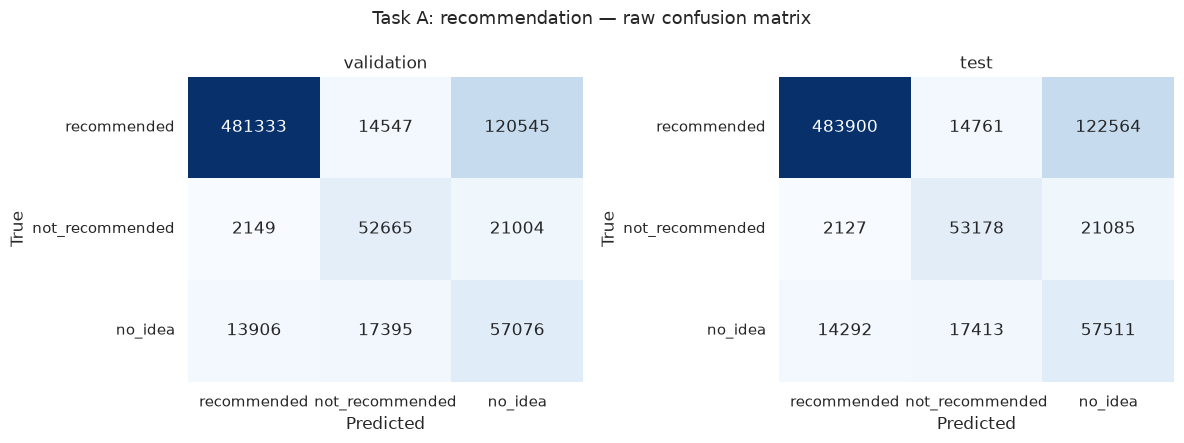

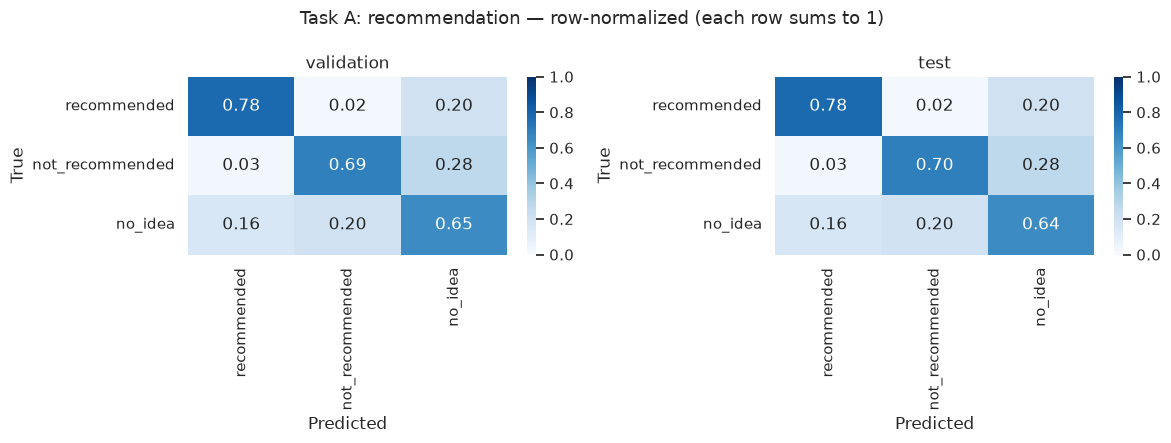

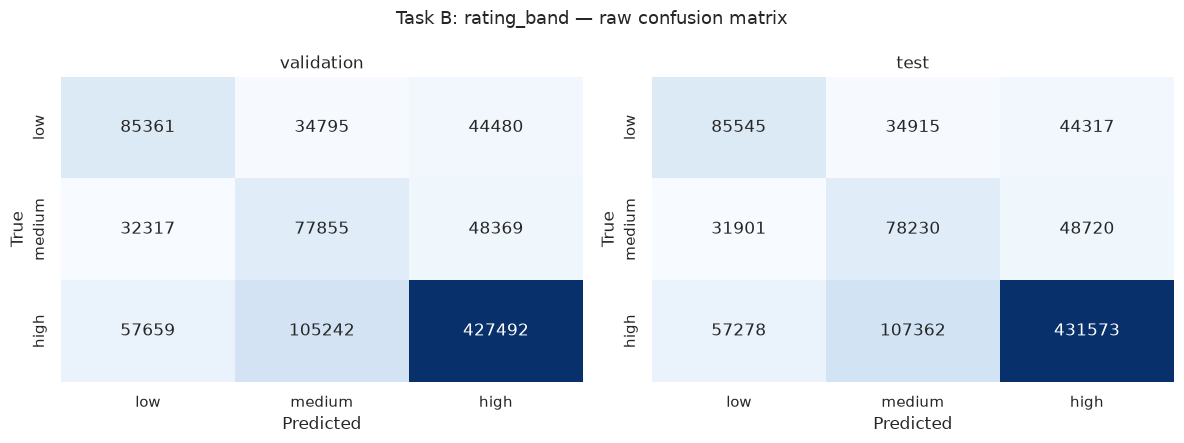

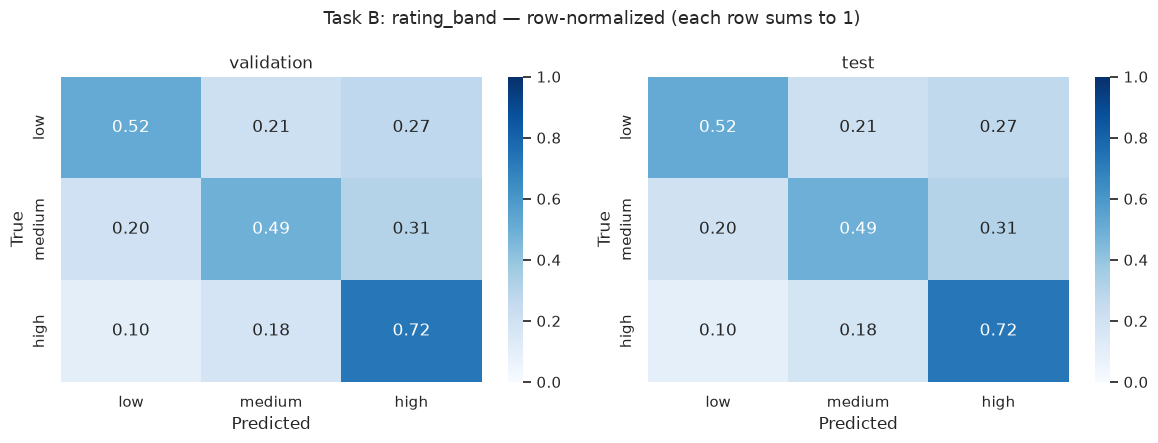

In [6]:
# ============================================================
# 03_baselines.ipynb — Cell 6: Confusion Matrix Visualization
# ============================================================
# Goal:
#   - plot raw and row-normalized confusion matrices for both tasks
#   - compare validation and test side by side
#
# Two plots are displayed inline. No files are written.
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", context="notebook")

# --- 1. Helper to plot a 2x2 grid of raw confusion matrices ------------
def plot_raw_confusions(
    title: str,
    labels: list[str],
    val_cm: list[list[int]],
    test_cm: list[list[int]],
) -> None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, cm, name in zip(axes, [val_cm, test_cm], ["validation", "test"]):
        sns.heatmap(
            np.array(cm),
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=labels,
            yticklabels=labels,
            cbar=False,
            ax=ax,
        )
        ax.set_title(f"{name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
    fig.suptitle(f"{title} — raw confusion matrix", fontsize=13)
    plt.tight_layout()
    plt.show()


# --- 2. Helper to plot a 2x2 grid of row-normalized confusion matrices -
def plot_normalized_confusions(
    title: str,
    labels: list[str],
    val_cm: list[list[int]],
    test_cm: list[list[int]],
) -> None:
    def row_normalize(cm: list[list[int]]) -> np.ndarray:
        arr = np.array(cm, dtype=float)
        row_sums = arr.sum(axis=1, keepdims=True)
        # Avoid division by zero if a row is empty (should not happen here).
        row_sums[row_sums == 0] = 1
        return arr / row_sums

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, cm, name in zip(axes, [val_cm, test_cm], ["validation", "test"]):
        norm = row_normalize(cm)
        sns.heatmap(
            norm,
            annot=True,
            fmt=".2f",
            cmap="Blues",
            vmin=0,
            vmax=1,
            xticklabels=labels,
            yticklabels=labels,
            cbar=True,
            ax=ax,
        )
        ax.set_title(f"{name}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
    fig.suptitle(f"{title} — row-normalized (each row sums to 1)", fontsize=13)
    plt.tight_layout()
    plt.show()


# --- 3. Task A: recommendation ------------------------------------------
plot_raw_confusions(
    title="Task A: recommendation",
    labels=LABELS,
    val_cm=metrics_rec_val["confusion_matrix"],
    test_cm=metrics_rec_test["confusion_matrix"],
)

plot_normalized_confusions(
    title="Task A: recommendation",
    labels=LABELS,
    val_cm=metrics_rec_val["confusion_matrix"],
    test_cm=metrics_rec_test["confusion_matrix"],
)

# --- 4. Task B: rating_band ---------------------------------------------
plot_raw_confusions(
    title="Task B: rating_band",
    labels=LABELS_BAND,
    val_cm=metrics_band_val["confusion_matrix"],
    test_cm=metrics_band_test["confusion_matrix"],
)

plot_normalized_confusions(
    title="Task B: rating_band",
    labels=LABELS_BAND,
    val_cm=metrics_band_val["confusion_matrix"],
    test_cm=metrics_band_test["confusion_matrix"],
)

In [7]:
# ============================================================
# 03_baselines.ipynb — Cell 7: Save Models & Metrics
# ============================================================
# Writes four files to artifacts/:
#   - tfidf_vectorizer.joblib
#   - tfidf_recommendation.joblib
#   - tfidf_rating_band.joblib
#   - baseline_metrics.json
#
# These are the artifacts consumed by the offline inference script
# and by the later comparison with the Transformer baselines.
# ============================================================

import datetime
import json
import joblib

# --- 1. Ensure artifacts/ exists -------------------------------------------
ARTIFACTS_DIR.mkdir(parents=True, exist_ok=True)

# --- 2. Save the vectorizer first ------------------------------------------
# A baseline model is useless without its vectorizer: at inference time,
# the same vocabulary and IDF weights must be applied to new text.
VECTORIZER_PATH = ARTIFACTS_DIR / "tfidf_vectorizer.joblib"
joblib.dump(word_vec, VECTORIZER_PATH, compress=3)
print(f"Saved vectorizer : {VECTORIZER_PATH}")
print(f"  size           : {VECTORIZER_PATH.stat().st_size / 1024**2:.1f} MB")

# --- 3. Save the two LogisticRegression models ----------------------------
joblib.dump(model_rec,  TFIDF_REC_PATH,  compress=3)
joblib.dump(model_band, TFIDF_BAND_PATH, compress=3)
print(f"Saved Task A     : {TFIDF_REC_PATH}")
print(f"  size           : {TFIDF_REC_PATH.stat().st_size / 1024**2:.1f} MB")
print(f"Saved Task B     : {TFIDF_BAND_PATH}")
print(f"  size           : {TFIDF_BAND_PATH.stat().st_size / 1024**2:.1f} MB")
print()

# --- 4. Build the baseline_metrics.json payload ---------------------------
baseline_metrics = {
    "generated_at_utc": datetime.datetime.now(datetime.UTC).isoformat().replace("+00:00", "Z"),
    "seeds": {
        "SPLIT_SEED": SPLIT_SEED,
        "MODEL_SEED": MODEL_SEED,
    },
    "vectorizer": {
        "analyzer": "word",
        "ngram_range": [1, 2],
        "min_df": 5,
        "max_df": 0.95,
        "max_features": 150_000,
        "sublinear_tf": True,
        "actual_vocab_size": int(len(word_vec.vocabulary_)),
        "artifact_path": str(VECTORIZER_PATH.relative_to(PROJECT_ROOT)),
    },
    "recommendation": {
        "classes_order": list(model_rec.classes_),
        "artifact_path": str(TFIDF_REC_PATH.relative_to(PROJECT_ROOT)),
        "training": {
            "n_train": int(X_train_rec.shape[0]),
            "n_features": int(X_train_rec.shape[1]),
            "class_weight": "balanced",
            "solver": "saga",
            "tol": 1e-3,
            "max_iter": 1000,
            "n_iter_actual": int(model_rec.n_iter_[0]),
            "converged": bool(model_rec.n_iter_[0] < 1000),
            "fit_time_note": "reported in notebook; not persisted",
        },
        "validation": metrics_rec_val,
        "test": metrics_rec_test,
    },
    "rating_band": {
        "classes_order": list(model_band.classes_),
        "artifact_path": str(TFIDF_BAND_PATH.relative_to(PROJECT_ROOT)),
        "ordinal_encoding": BAND_ORDINAL,
        "training": {
            "n_train": int(X_train_band.shape[0]),
            "n_features": int(X_train_band.shape[1]),
            "class_weight": "balanced",
            "solver": "saga",
            "tol": 1e-2,
            "max_iter": 500,
            "n_iter_actual": int(model_band.n_iter_[0]),
            "converged": bool(model_band.n_iter_[0] < 500),
        },
        "validation": {**metrics_band_val, "ordinal_distance_error": ord_val},
        "test":       {**metrics_band_test, "ordinal_distance_error": ord_test},
    },
}

# --- 5. Write the JSON ----------------------------------------------------
with BASELINE_METRICS_JSON.open("w", encoding="utf-8") as f:
    json.dump(baseline_metrics, f, ensure_ascii=False, indent=2)

print(f"Saved metrics    : {BASELINE_METRICS_JSON}")
print(f"  size           : {BASELINE_METRICS_JSON.stat().st_size / 1024:.1f} KB")
print()

# --- 6. Post-write verification: reload everything and predict on 3 rows -
print("Post-write verification (reload and predict on 3 rows):")
vec_reload  = joblib.load(VECTORIZER_PATH)
rec_reload  = joblib.load(TFIDF_REC_PATH)
band_reload = joblib.load(TFIDF_BAND_PATH)

sample_texts = test["body_normalized"].fill_null("").head(3).to_list()
X_sample = vec_reload.transform(sample_texts)

print(f"  X_sample shape         : {X_sample.shape}")
print(f"  recommendation predict : {rec_reload.predict(X_sample).tolist()}")
print(f"  rating_band predict    : {band_reload.predict(X_sample).tolist()}")
print()
print("All artifacts reloaded and produced predictions successfully.")
print()
print("=" * 60)
print("Part C — baseline notebook complete.")
print("=" * 60)

Saved vectorizer : /home/jvd/Desktop/persian-nlp-pipeline/artifacts/tfidf_vectorizer.joblib
  size           : 1.9 MB
Saved Task A     : /home/jvd/Desktop/persian-nlp-pipeline/artifacts/tfidf_recommendation.joblib
  size           : 1.6 MB
Saved Task B     : /home/jvd/Desktop/persian-nlp-pipeline/artifacts/tfidf_rating_band.joblib
  size           : 1.6 MB

Saved metrics    : /home/jvd/Desktop/persian-nlp-pipeline/artifacts/baseline_metrics.json
  size           : 5.9 KB

Post-write verification (reload and predict on 3 rows):
  X_sample shape         : (3, 150000)
  recommendation predict : ['recommended', 'recommended', 'recommended']
  rating_band predict    : ['high', 'high', 'high']

All artifacts reloaded and produced predictions successfully.

Part C — baseline notebook complete.
